In [1]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:

base_path = "../../../data/ObjectDetectionV3"
# base_path = "database"
df_annotations = pd.read_csv(os.path.join(base_path, "annotation_merged_furniture.csv"))
df_images = pd.read_csv(os.path.join(base_path, "images.csv"))

with open(os.path.join(base_path, "train_test_split.json"), "rt") as f:
    train_test_split = json.load(f)

In [3]:
def get_split(img_id):
    if img_id in train_test_split["train"]:
        return "train"
    elif img_id in train_test_split["test"]:
        return "test"
    else:
        return "nonused"

In [4]:
df_images["split"] = df_images["id"].apply(get_split)

In [5]:
df_images.head()

,id,name,width,height,batch,folder,split
0,bdd640fb-0667-4ad1-9c80-317fa3b1799d,Cam3_H243_discount_14.png,640.0,480.0,batch1_10.5,batch1,train
1,fc377a4c-4a15-444d-85e7-ce8a3a578a8e,Cam3_H243_discount_15.png,640.0,480.0,batch1_10.5,batch1,train
2,ff50bde4-3825-47b8-9cab-cc97663f1c97,Cam3_H243_discount_16.png,640.0,480.0,batch1_10.5,batch1,train
3,5cec4eb5-edd9-4831-9ca3-5cfb04fc6d82,Cam3_H243_discount_17.png,640.0,480.0,batch1_10.5,batch1,train
4,b92da22b-21df-406f-8a0b-3c3336d8393a,Cam3_H243_discount_18.png,640.0,480.0,batch1_10.5,batch1,train


In [6]:
df_annotations.head()

,label,occluded,truncated,not_ground,occupied,occupied_by_person,ID,xtl,ytl,xbr,ybr,x,y,img_id,id
0,bag,False,False,False,False,False,9,346.45,165.42,393.28,220.25,369.91,191.48,bdd640fb-0667-4ad1-9c80-317fa3b1799d,bd9c66b3-ad3c-4d6d-9a3d-1fa7bc8960a9
1,bag,True,False,False,False,False,10,329.10,133.89,369.63,170.60,350.15,150.37,bdd640fb-0667-4ad1-9c80-317fa3b1799d,972a8469-1641-4f82-8b9d-2434e465e150
2,laptop_closed,False,False,False,False,False,19,224.38,287.20,280.56,324.61,253.60,305.88,bdd640fb-0667-4ad1-9c80-317fa3b1799d,17fc695a-07a0-4a6e-8822-e8f36c031199
3,laptop_opened,False,False,False,False,False,18,197.42,191.27,249.80,228.00,224.38,210.00,bdd640fb-0667-4ad1-9c80-317fa3b1799d,9a1de644-815e-46d1-bb8f-aa1837f8a88b
4,laptop_opened,False,False,False,False,False,17,153.20,278.16,209.40,323.11,183.93,302.13,bdd640fb-0667-4ad1-9c80-317fa3b1799d,b74d0fb1-32e7-4629-8fad-c1a606cb0fb3


## camera distribution


In [7]:
img_names = df_images["name"].values
img_names = np.array(list(map(lambda x: x.lower(), img_names)))

In [8]:
img_names.shape

(1457,)

In [9]:
cams = sum(["pg1" in i for i in img_names]) + sum(["cam1" in i for i in img_names]), sum(["cam2" in i for i in img_names]), sum(["cam3" in i for i in img_names])
cams, sum(cams)

((898, 90, 419), 1407)

In [10]:
def get_camera_type(img_name: str) -> str:
    img_name_lower = img_name.lower()
    if "pg1" in img_name_lower or "cam1" in img_name_lower:
        return "cam1"
    elif "cam2" in img_name_lower:
        return "cam2"
    elif "cam3" in img_name_lower:
        return "cam3"
    else:
        return "unknown"

In [11]:
df_images["camera_type"] = df_images["name"].apply(get_camera_type)

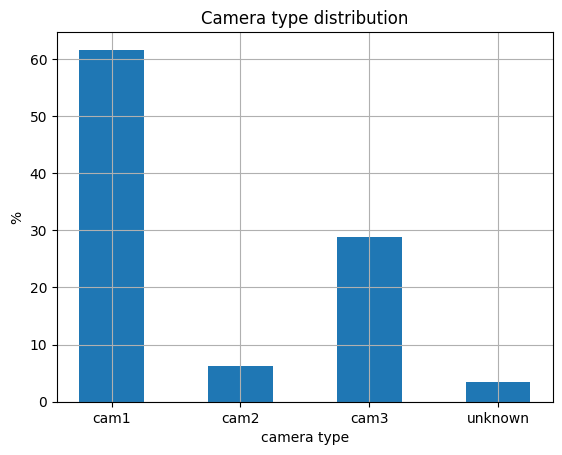

In [12]:
def f(df):
    value_counts = df.value_counts().sort_index()
    total_values = value_counts.sum()
    percentages = (value_counts / total_values) * 100
    return percentages

percentages = f(df_images["camera_type"])

plt.figure()
plt.bar(percentages.index, percentages.values, width=0.5, align='center')

# Customize labels and title
plt.grid()
plt.xlabel('camera type')
plt.ylabel('%')
plt.title('Camera type distribution');

<Figure size 640x480 with 0 Axes>

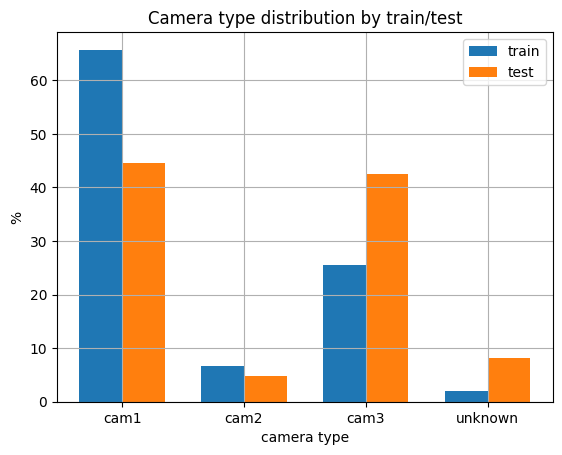

In [13]:
percentages_train = f(df_images[df_images["split"] == "train"]["camera_type"])
percentages_test = f(df_images[df_images["split"] == "test"]["camera_type"])

x = np.arange(len(percentages_train.index))  # the label locations
width = 0.35

plt.figure()
fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, percentages_train.values, width, label='train')
rects2 = ax.bar(x + width/2, percentages_test.values, width, label='test')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Scores')
ax.set_title('Scores by group and gender')
ax.set_xticks(x)
ax.set_xticklabels(percentages_train.index)
ax.legend()

# Customize labels and title
plt.grid()
plt.xlabel('camera type')
plt.ylabel('%')
plt.title('Camera type distribution by train/test');

## altitude distribution

In [14]:
img_names.shape[0] == sum(["_h" in i.lower() for i in img_names])

False

In [15]:
def get_altitude(img_name: str) -> int:
    substrings = img_name.lower().split("_")
    altitude = -1
    for i in range(len(substrings)):
        if substrings[i][0] == "h":
            try:
                altitude = int(substrings[i][1:])
            except ValueError:
                pass
        elif substrings[i][:3] == "cam":
            try:
                altitude = int(substrings[i + 1])
            except ValueError:
                pass
                
        
        if altitude > 0:
            break
    return altitude

In [16]:
df_images["altitude"] = df_images["name"].apply(get_altitude)

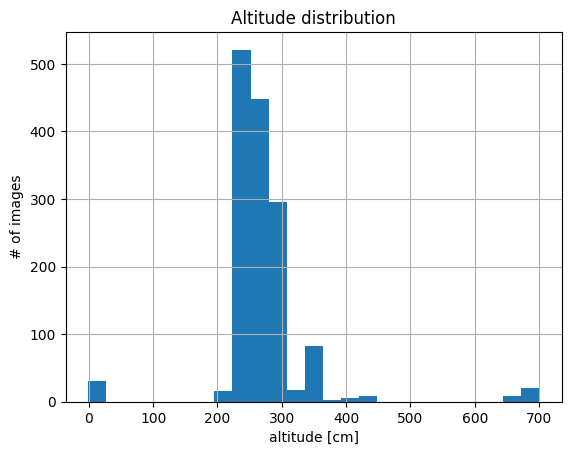

In [17]:
plt.hist(df_images["altitude"].values, bins=25);
plt.grid()
plt.xlabel('altitude [cm]')
plt.ylabel('# of images')
plt.title('Altitude distribution');

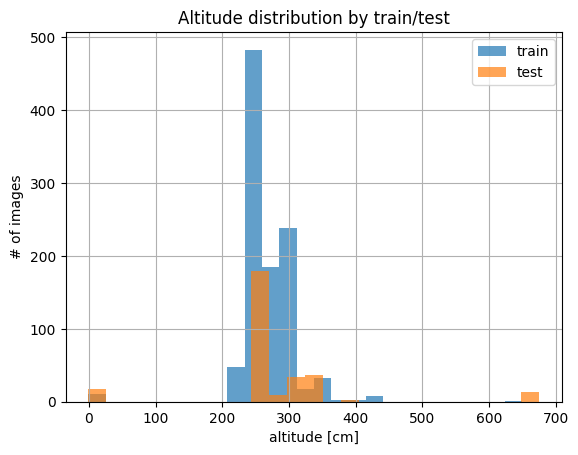

In [24]:
plt.hist(df_images[df_images["split"] == "train"]["altitude"].values, alpha=0.7, bins=25, label="train");
plt.hist(df_images[df_images["split"] == "test"]["altitude"].values, alpha=0.7, bins=25, label="test");
plt.grid()
plt.legend()
plt.xlabel('altitude [cm]')
plt.ylabel('# of images')
plt.title('Altitude distribution by train/test');

## number of chairs and tables distribution

In [19]:
df_annotations = df_annotations[df_annotations["label"].isin(["chair", "table"])]

In [20]:
# Count occurrences of each label for each img_id
pivot_table = pd.crosstab(df_annotations['img_id'], df_annotations['label'])

# Reset index to get img_id as a regular column
pivot_table = pivot_table.reset_index()

# Rename columns to match the required format
pivot_table.columns.name = None  # Remove the 'label' name from columns
pivot_table.columns = ['img_id', 'value_count_chair', 'value_count_table']

# Display the resulting DataFrame
pivot_table.head()

,img_id,value_count_chair,value_count_table
0,0032ef19-3a16-4059-bd21-a6c80891807e,11,3
1,00456415-ca69-4624-bd07-dc1e5404a79e,9,7
2,00507e5b-bbf8-42a8-94fc-14f015644bb6,9,5
3,008f03ca-8a32-405e-ab40-335213445e51,7,1
4,00d52f8c-bc35-45d9-948d-83ea35ce13ad,9,8


In [21]:
df_images = pd.merge(
    df_images,
    pivot_table,
    how="left",
    left_on="id",
    right_on="img_id"
)

df_images.fillna(0, inplace=True)
df_images.drop(columns=["img_id"], inplace=True)
df_images.head(-5)

,id,name,width,height,batch,folder,split,camera_type,altitude,value_count_chair,value_count_table
0,bdd640fb-0667-4ad1-9c80-317fa3b1799d,Cam3_H243_discount_14.png,640.0,480.0,batch1_10.5,batch1,train,cam3,243,7.0,1.0
1,fc377a4c-4a15-444d-85e7-ce8a3a578a8e,Cam3_H243_discount_15.png,640.0,480.0,batch1_10.5,batch1,train,cam3,243,7.0,1.0
2,ff50bde4-3825-47b8-9cab-cc97663f1c97,Cam3_H243_discount_16.png,640.0,480.0,batch1_10.5,batch1,train,cam3,243,7.0,1.0
3,5cec4eb5-edd9-4831-9ca3-5cfb04fc6d82,Cam3_H243_discount_17.png,640.0,480.0,batch1_10.5,batch1,train,cam3,243,7.0,1.0
4,b92da22b-21df-406f-8a0b-3c3336d8393a,Cam3_H243_discount_18.png,640.0,480.0,batch1_10.5,batch1,train,cam3,243,7.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...
1447,f899ab34-f6b5-43c8-903c-c094f92ca0ed,PG1_dev_H250_HD_designed_Occlusion_1509284882-...,0.0,0.0,batch4_22.5,9,nonused,cam1,250,0.0,0.0
1448,cddbceac-0571-48e4-9ac7-25b03648762a,PG1_dev_H250_HD_designed_Occlusion_1513600067-...,0.0,0.0,batch4_22.5,9,nonused,cam1,250,0.0,0.0
1449,4fd3c815-60b2-4b64-8df6-5a2b3ef786cb,PG1_dev_H250_VLC_Walk_Lobby_5m_stitch_L_NY_15s...,0.0,0.0,batch4_22.5,9,nonused,cam1,250,0.0,0.0
1450,6066eb28-1f72-4864-b77c-82a7cd38b317,PG1_dev_H250_VLC_Walk_Q_5m_stitch_L_NY_15stnd_...,0.0,0.0,batch4_22.5,9,nonused,cam1,250,0.0,0.0


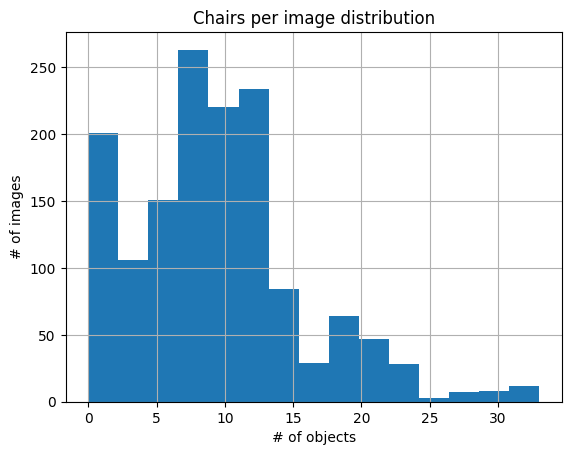

In [30]:
plt.hist(df_images["value_count_chair"].values, bins=15);
plt.grid()
plt.xlabel('# of objects')
plt.ylabel('# of images')
plt.title('Chairs per image distribution');

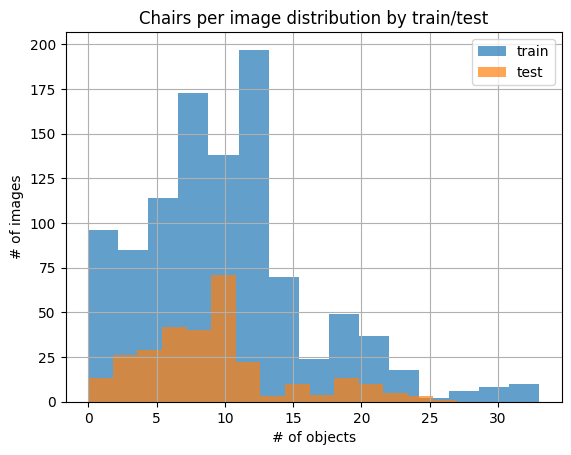

In [35]:
plt.hist(df_images[df_images["split"] == "train"]["value_count_chair"].values, alpha=0.7, bins=15, label="train");
plt.hist(df_images[df_images["split"] == "test"]["value_count_chair"].values, alpha=0.7, bins=15, label="test");
plt.grid()
plt.legend()
plt.xlabel('# of objects')
plt.ylabel('# of images')
plt.title('Chairs per image distribution by train/test');

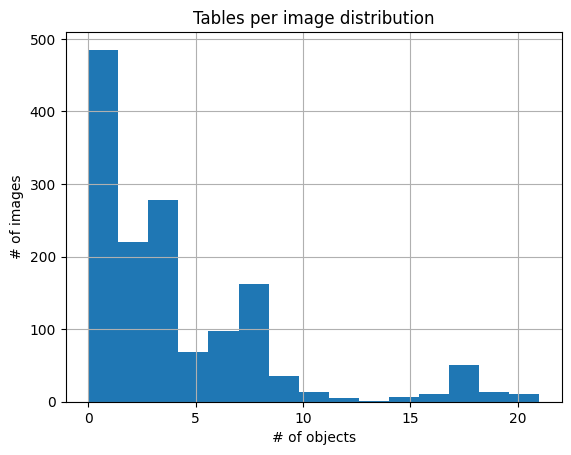

In [36]:
plt.hist(df_images["value_count_table"].values, bins=15);
plt.grid()
plt.xlabel('# of objects')
plt.ylabel('# of images')
plt.title('Tables per image distribution');

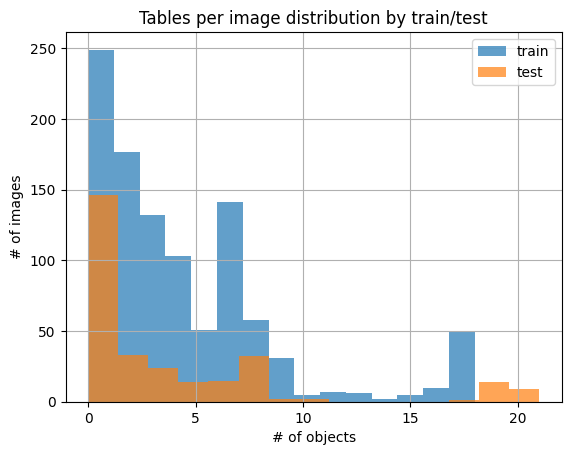

In [37]:
plt.hist(df_images[df_images["split"] == "train"]["value_count_table"].values, alpha=0.7, bins=15, label="train");
plt.hist(df_images[df_images["split"] == "test"]["value_count_table"].values, alpha=0.7, bins=15, label="test");
plt.grid()
plt.legend()
plt.xlabel('# of objects')
plt.ylabel('# of images')
plt.title('Tables per image distribution by train/test');